# 16. Remaining useful life and the quantity it depends on

This is the project's first direct attempt at remaining useful life. The question is whether a time-series model can accurately predict how long a bearing has left. Notebooks 13, 14 and 15 all ended by naming it the next experiment, and it needs no new data. XJTU-SY gives fifteen bearings watched from new to failure, one snapshot per minute, so every unit has a full trajectory and a known end. Notebook 14 added two more things that each unit now carries: a stage-1 alarm time and a stage-2 race label.

The answer is no, not as a number of minutes. The reason is arithmetic before it is statistical.

Elapsed time is known exactly. A prediction of remaining life at minute t is therefore also a prediction of total life: `RUL_hat(t) = L_hat(t) − t`, and the two errors are the same number to the last decimal place. Predicting RUL on run-to-failure data is predicting how long the bearing will live. That is a much harder question than how damaged the bearing is now, and the two are easy to confuse when the metric is reported as a single MAE.

The spread of lifetimes makes this concrete. The fifteen lifetimes span 42 to 2538 minutes, a factor of 60, and most of that spread is set before any of the vibration features move. The operating point explains a good deal of it (mean life is 123, 313 and 1407 minutes at the three conditions) but far from all: within the slowest condition alone, units die at 114 and at 2538 minutes.

The notebook is therefore built around baselines rather than around a model. The test is whether the vibration state beats a clock that has never seen it. We compare four predictors, all evaluated leave-one-bearing-out in the project's standard protocol:

- Median lifetime: assume this unit lasts as long as the fleet median, and count down.
- Median at this condition: the same, using only training units at the same speed and load.
- Learned clock: a forest given minutes-run and the operating point, and nothing else.
- Two-channel state: the same forest plus everything notebook 14 built: the stage-1 anomaly score and its trend, the nine envelope order bands referenced to the unit's own healthy baseline, RMS and kurtosis, and minutes since the alarm.

The last contains the third, so the comparison is nested and any gain is attributable to vibration.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

OUT = pathlib.Path("../data/processed")
ds = pd.read_csv(OUT / "xjtu_envelope_features.csv")     # built by notebook 13

FAULT = {"Bearing1_1": "OR", "Bearing1_2": "OR", "Bearing1_3": "OR",
         "Bearing1_4": "cage", "Bearing1_5": "IR+OR", "Bearing2_1": "IR",
         "Bearing2_2": "OR", "Bearing2_3": "cage", "Bearing2_4": "OR",
         "Bearing2_5": "OR", "Bearing3_1": "OR", "Bearing3_2": "compound",
         "Bearing3_3": "IR", "Bearing3_4": "IR", "Bearing3_5": "OR"}
BEAR = sorted(ds["Bearing"].unique())
RACE = [b for b in BEAR if FAULT[b] in ("OR", "IR")]
G = {b: ds[ds["Bearing"] == b].sort_values("Snapshot").reset_index(drop=True) for b in BEAR}
N = {b: len(G[b]) for b in BEAR}                          # lifetime in minutes
COND = {b: G[b]["Cond"].iloc[0] for b in BEAR}

ENV = ["H_BPFO", "H_BPFI", "H_FR", "H_BPFO_h2", "H_BPFI_h2", "H_BSF", "H_FTF",
       "H_BPFI_sb1", "H_BPFO_sb1"]
DETECT = ["H_RMS", "H_Kurt"]
K, W = 20, 10
RF = dict(n_estimators=300, random_state=0, n_jobs=-1, min_samples_leaf=2)


class Exceedance:
    """Robust per-feature z over the unit's own healthy baseline (notebook 07)."""

    def fit(self, A):
        self.med = np.median(A, axis=0)
        self.mad = np.maximum(1.4826 * np.median(np.abs(A - self.med), axis=0), 0.1)
        return self

    def score(self, A):
        return ((A - self.med) / self.mad).max(axis=1)


ALARM, ANOM = {}, {}
for b in BEAR:
    A = G[b][DETECT].to_numpy()
    z = Exceedance().fit(A[:K]).score(A)
    ANOM[b] = z
    flags = z[K:] > np.quantile(z[:K], 0.99)
    c = np.convolve(flags.astype(float), np.ones(W) / W, mode="valid")
    ALARM[b] = int(np.flatnonzero(c >= 0.5)[0]) + K       # notebook 14's stage-1 alarm


def frame(b):
    """One row per minute: everything an operator would hold at that moment."""
    n, t = N[b], np.arange(N[b])
    A = G[b][ENV].to_numpy()
    R = G[b][DETECT].to_numpy()
    z = ANOM[b]
    slope = np.zeros(n)
    for i in range(n):                                    # trend of the alarm channel
        lo = max(0, i - 9)
        if i - lo >= 2:
            slope[i] = np.polyfit(np.arange(lo, i + 1), z[lo:i + 1], 1)[0]
    f = pd.DataFrame(A - np.median(A[:K], axis=0), columns=[c + "_d" for c in ENV])
    dr = R - np.median(R[:K], axis=0)
    f["RMS_d"], f["Kurt_d"] = dr[:, 0], dr[:, 1]
    f["anom"], f["anom_slope"] = z, slope
    f["elapsed"] = t                                      # minutes run, known exactly
    f["since_alarm"] = np.maximum(t - ALARM[b], 0)
    f["alarmed"] = (t >= ALARM[b]).astype(int)
    f["fr_Hz"] = G[b]["fr_Hz"].to_numpy()
    f["RUL"] = (n - 1) - t                                # the target, in minutes
    f["Bearing"] = b
    return f


DF = pd.concat([frame(b) for b in BEAR], ignore_index=True)
FEATS = [c for c in DF.columns if c not in ("RUL", "Bearing")]
CLOCK = ["elapsed", "fr_Hz"]                              # operating point + minutes run
DF["pos"] = DF["elapsed"] / DF["Bearing"].map(N).sub(1)   # fraction of life elapsed

# --- one leave-one-bearing-out pass, reused by every figure below.
# Each tree in the forest is a vote on remaining life, so the spread across trees is the
# model's own uncertainty, and a low quantile of it is a conservative bound with no extra computation.
QS = [0.05, 0.10, 0.20, 0.30, 0.50]
P = {}
for held in BEAR:
    tr = DF["Bearing"].isin([o for o in BEAR if o != held])
    hm = DF["Bearing"] == held
    Xh = DF.loc[hm, FEATS].to_numpy()
    m = RandomForestRegressor(**RF).fit(DF.loc[tr, FEATS], DF.loc[tr, "RUL"])
    trees = np.stack([t.predict(Xh) for t in m.estimators_])
    clk = RandomForestRegressor(**RF).fit(DF.loc[tr, CLOCK], DF.loc[tr, "RUL"]) \
        .predict(DF.loc[hm, CLOCK])
    t_el = DF.loc[hm, "elapsed"].to_numpy()
    same = [N[o] for o in BEAR if o != held and COND[o] == COND[held]]
    P[held] = dict(y=DF.loc[hm, "RUL"].to_numpy(), t=t_el, pos=DF.loc[hm, "pos"].to_numpy(),
                   state=trees.mean(axis=0), clock=clk,
                   q={q: np.quantile(trees, q, axis=0) for q in QS},
                   med_all=np.maximum(np.median([N[o] for o in BEAR if o != held]) - 1 - t_el, 0),
                   med_cond=np.maximum(np.median(same) - 1 - t_el, 0),
                   post=t_el >= ALARM[held])

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
FCOLOR = {"OR": C_BLUE, "IR": C_ORANGE, "cage": "#7a9e3f",
          "IR+OR": "#8f6bb5", "compound": MUTED}
BINS = [(0.0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.0)]
LAB = [f"{a:.0%}-{b:.0%}" for a, b in BINS]

# RUL_hat(t) = L_hat(t) - t with t known exactly, so the two errors are the same number.
gap = max(abs(np.abs(P[b]["state"] - P[b]["y"]).mean()
              - np.abs(P[b]["state"] + P[b]["t"] - (N[b] - 1)).mean()) for b in BEAR)
print(f"{DF.shape[0]} snapshots x {len(FEATS)} features, 15 units, "
      f"lifetimes {min(N.values())}-{max(N.values())} min ({max(N.values()) / min(N.values()):.0f}x)")
print(f"RUL error and lifetime error differ by at most {gap:.6f} minutes - they are one quantity")

9216 snapshots x 17 features, 15 units, lifetimes 42-2538 min (60x)
RUL error and lifetime error differ by at most 0.000000 minutes - they are one quantity


## Vibration state against the clock

Each predictor is scored twice: over the whole trajectory, which is the figure a paper usually reports, and over post-alarm snapshots only, which is the regime notebook 14's two-stage protocol defines, since stage 2 never runs until stage 1 has fired.

Errors are shown per unit rather than pooled, because pooling over lifetimes that differ by 60x lets three long bearings decide the average. The bar is the median across the fifteen units, and every unit is plotted behind it.

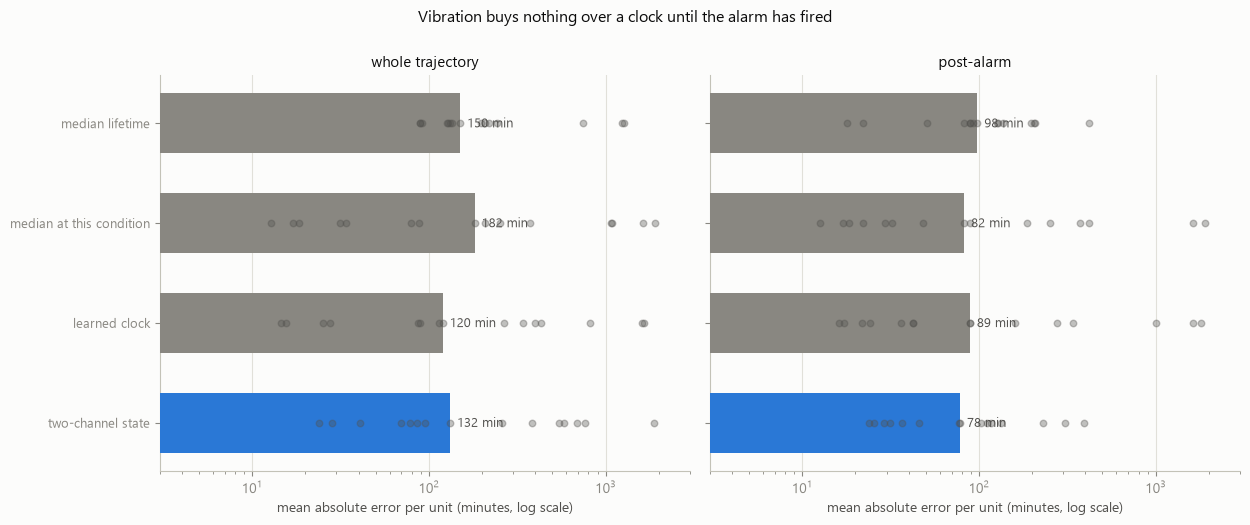

whole trajectory: learned clock 120 min vs two-channel state 132 min
post-alarm      : learned clock 89 min vs two-channel state 78 min


trained on post-alarm rows only: clock 80 min vs two-channel state 57 min


scope,whole trajectory,post-alarm
model,,
median lifetime,150,98
median at this condition,182,82
learned clock,120,89
two-channel state,132,78


In [2]:
MODELS = [("median lifetime", "med_all"), ("median at this condition", "med_cond"),
          ("learned clock", "clock"), ("two-channel state", "state")]

rows = []
for b in BEAR:
    d = P[b]
    for name, key in MODELS:
        for scope, s in (("whole trajectory", np.ones_like(d["post"])), ("post-alarm", d["post"])):
            e = np.abs(d[key][s] - d["y"][s])
            rows.append(dict(Bearing=b, fault=FAULT[b], model=name, scope=scope,
                             mae=e.mean(), late=(d[key][s] > d["y"][s]).mean()))
base = pd.DataFrame(rows)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.6, 5.2), sharey=True)
for ax, scope in ((axa, "whole trajectory"), (axb, "post-alarm")):
    s = base[base["scope"] == scope]
    y = np.arange(len(MODELS))
    med = [s[s["model"] == n]["mae"].median() for n, _ in MODELS]
    ax.barh(y, med, height=0.6, zorder=3,
            color=[MUTED if n != "two-channel state" else C_BLUE for n, _ in MODELS])
    for i, b_ in enumerate(med):
        ax.annotate(f"{b_:.0f} min", (b_, i), xytext=(5, -3), textcoords="offset points",
                    fontsize=9, color=INK2)
    for i, (n, _) in enumerate(MODELS):                  # every unit, behind the median
        ax.scatter(s[s["model"] == n]["mae"], np.full((s["model"] == n).sum(), i),
                   s=22, color=INK2, alpha=0.35, zorder=4)
    ax.set_yticks(y, [n for n, _ in MODELS], fontsize=9.5)
    ax.set_xscale("log")
    ax.set_xlim(3, 3000)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("mean absolute error per unit (minutes, log scale)")
    ax.set_title(scope, fontsize=10.5)
axa.invert_yaxis()
fig.suptitle("Vibration buys nothing over a clock until the alarm has fired", fontsize=11.5, y=1.0)
plt.tight_layout()
plt.show()

t = base.pivot_table(index="model", columns="scope", values="mae", aggfunc="median")
t = t.reindex([n for n, _ in MODELS])[["whole trajectory", "post-alarm"]]
print(f"whole trajectory: learned clock {t.loc['learned clock', 'whole trajectory']:.0f} min "
      f"vs two-channel state {t.loc['two-channel state', 'whole trajectory']:.0f} min")
print(f"post-alarm      : learned clock {t.loc['learned clock', 'post-alarm']:.0f} min "
      f"vs two-channel state {t.loc['two-channel state', 'post-alarm']:.0f} min")
# a model trained only on post-alarm rows, which is how it would actually be deployed
pa = []
for b in BEAR:
    tr = DF["Bearing"].isin([o for o in BEAR if o != b]) & (DF["alarmed"] == 1)
    hm = (DF["Bearing"] == b) & (DF["alarmed"] == 1)
    for nm, cols in (("clock", CLOCK), ("state", FEATS)):
        q = RandomForestRegressor(**RF).fit(DF.loc[tr, cols], DF.loc[tr, "RUL"])             .predict(DF.loc[hm, cols])
        pa.append(dict(Bearing=b, model=nm, mae=np.abs(q - DF.loc[hm, "RUL"]).mean()))
pa = pd.DataFrame(pa).groupby("model")["mae"].median()
print(f"trained on post-alarm rows only: clock {pa['clock']:.0f} min "
      f"vs two-channel state {pa['state']:.0f} min")
t.style.format("{:.0f}")

Over a whole trajectory the vibration state is worse than the clock it contains: 132 minutes against 120. The scatter of per-unit errors shows why no average decides this: the same model is out by 15 minutes on one unit and by 1600 on another.

After the alarm the state beats the clock. This is the result the two-stage protocol was built to expose. Evaluated only on post-alarm snapshots, the same model beats the clock 78 minutes to 89. A model trained only on post-alarm rows, which is how it would be deployed since stage 2 never runs before stage 1 fires, reaches 57 minutes against the clock's 80. Vibration is informative about remaining life only once there is damage for it to be informative about. Before the alarm it is noise added to a clock.

This splits the RUL problem the way notebook 14 split detection from attribution. It also leaves the half that the clock was doing. A prediction of remaining life is a prediction of total life, so the next step is to check how good the total-life claim is.

## What the lifetime estimate claims

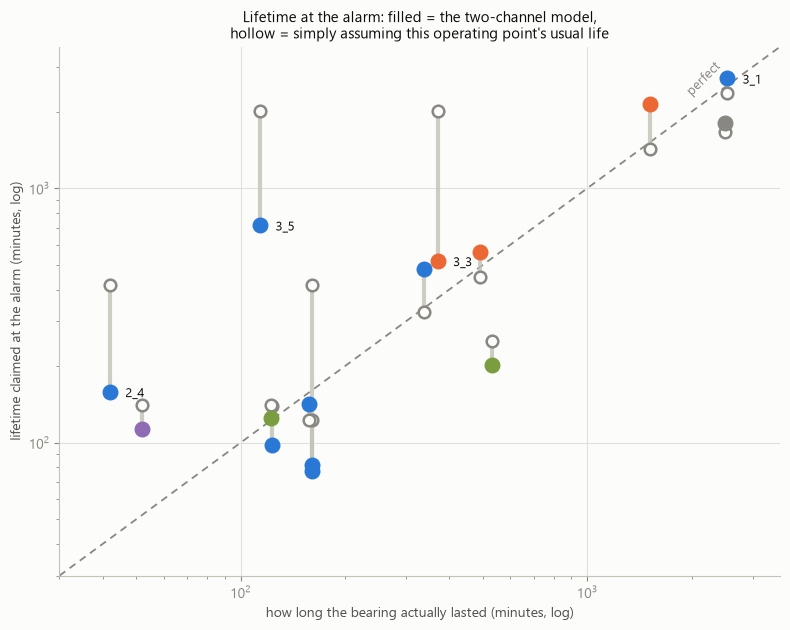

model : MAE   211 min, median   117, r2 +0.86
usual : MAE   385 min, median    88, r2 +0.29

both are flattered by the floor: at the alarm a unit has already survived 54 min (median), which is a free lower bound on its life
at the alarm the point RUL is optimistic on 9/15 units, median 1.73x the life that remained


,fault,life,run,model,usual,rul_true,rul_hat
Bearing,,,,,,,
Bearing1_1,OR,123,20,98,140,102,77
Bearing1_2,OR,161,38,77,122,122,38
Bearing1_3,OR,158,54,142,122,103,87
Bearing1_4,cage,122,48,125,140,73,76
Bearing1_5,IR+OR,52,25,113,140,26,87
Bearing2_1,IR,491,446,561,447,44,114
Bearing2_2,OR,161,20,81,415,140,60
Bearing2_3,cage,533,116,203,250,416,86
Bearing2_4,OR,42,25,159,415,16,133


In [3]:
# RUL_hat(t) + t is an estimate of total lifetime. Compare it at the alarm with the usual
# life of this operating point. The alarm is the first moment the question is live.
# Both are floored at the minutes already survived, which needs no model.
rows = []
for b in BEAR:
    d = P[b]
    i = np.flatnonzero(d["t"] == ALARM[b])[0]
    same = [N[o] for o in BEAR if o != b and COND[o] == COND[b]]
    rows.append(dict(Bearing=b, fault=FAULT[b], cond=COND[b], life=N[b], run=int(d["t"][i]),
                     model=float(d["state"][i] + d["t"][i]) + 1,
                     usual=max(float(np.median(same)), float(d["t"][i]) + 1),
                     rul_true=int(d["y"][i]), rul_hat=float(d["state"][i])))
lf = pd.DataFrame(rows).set_index("Bearing")

fig, ax = plt.subplots(figsize=(8.0, 6.4))
lim = (30, 3600)
ax.plot(lim, lim, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=2)
ax.text(2000, 2300, "perfect", color=MUTED, fontsize=9, rotation=45, rotation_mode="anchor")
for b in BEAR:
    r = lf.loc[b]
    ax.plot([r["life"]] * 2, [r["usual"], r["model"]], color=BASE, lw=3, alpha=0.8,
            solid_capstyle="round", zorder=3)
    ax.scatter([r["life"]], [r["usual"]], s=70, facecolors=SURFACE,
               edgecolors=MUTED, linewidths=1.8, zorder=4)
    ax.scatter([r["life"]], [r["model"]], s=110, color=FCOLOR[FAULT[b]], zorder=5)
for b in ("Bearing3_5", "Bearing3_3", "Bearing2_4", "Bearing3_1"):
    ax.annotate(b.replace("Bearing", ""), (lf.loc[b, "life"], lf.loc[b, "model"]),
                textcoords="offset points", xytext=(11, -4), fontsize=9, color=INK)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlim(*lim)
ax.set_ylim(*lim)
ax.set_xlabel("how long the bearing actually lasted (minutes, log)")
ax.set_ylabel("lifetime claimed at the alarm (minutes, log)")
ax.set_title("Lifetime at the alarm: filled = the two-channel model,\n"
             "hollow = simply assuming this operating point's usual life", fontsize=11)
plt.tight_layout()
plt.show()

for nm in ("model", "usual"):
    e = (lf[nm] - lf["life"]).abs()
    print(f"{nm:6s}: MAE {e.mean():5.0f} min, median {e.median():5.0f}, "
          f"r2 {r2_score(lf['life'], lf[nm]):+.2f}")
print(f"\nboth are flattered by the floor: at the alarm a unit has already survived "
      f"{lf['run'].median():.0f} min (median), which is a free lower bound on its life")
print(f"at the alarm the point RUL is optimistic on "
      f"{(lf['rul_hat'] > lf['rul_true']).sum()}/15 units, median "
      f"{(lf['rul_hat'] / lf['rul_true'].clip(lower=1)).median():.2f}x the life that remained")
lf[["fault", "life", "run", "model", "usual", "rul_true", "rul_hat"]].style.format(
    {"model": "{:.0f}", "usual": "{:.0f}", "rul_hat": "{:.0f}"})

The state adds lifetime information, but an average reports it poorly. Against simply assuming this operating point's usual life, the model cuts mean error from 385 to 211 minutes and lifts r² from +0.29 to +0.86, but its median error is worse: 117 minutes against 88. It gains robustness on the units the operating-point prior gets badly wrong and loses on the ordinary ones.

The labelled units show that trade. Bearing3_3 and Bearing3_5 live 371 and 114 minutes at a condition whose prior is 2006 minutes, and the model's correction is real but uneven: it calls 3_3 at 520 (most of the way back) and 3_5 at 717, still over by a factor of six. Bearing2_4 dies at 42 minutes, the shortest life in the set, and neither estimator gets near it (415 from the prior, 159 from the model).

Two cautions apply to this figure. First, both estimators benefit from a floor: at the alarm a unit has already survived a median of 54 minutes, and a bearing that has run 54 minutes will live at least 54 minutes. This floor needs no model. A large part of that +0.86 is arithmetic, not prognosis. Second, and more serious for anything that would act on the number: at the alarm the point estimate is optimistic on 9 of 15 units, claiming a median 1.73× the life that actually remained.

Optimism at a single moment could be chance. The next figure checks whether it is systematic, and whether the estimate improves as the end approaches, which a prognostic must do.

## Error as failure approaches

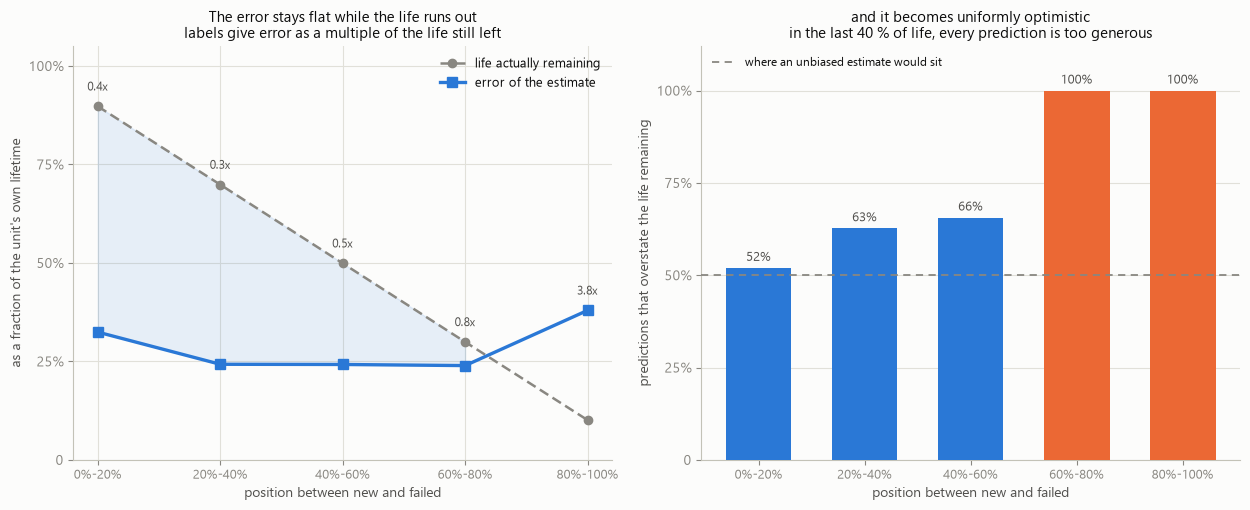

error as a multiple of the life still remaining, by position: 0%-20% 0.36x, 20%-40% 0.35x, 40%-60% 0.49x, 60%-80% 0.80x, 80%-100% 3.75x
optimistic predictions: 0%-20% 52%, 20%-40% 63%, 40%-60% 66%, 60%-80% 100%, 80%-100% 100%


,error / own lifetime,life remaining,optimistic
0%-20%,0.324,0.898,0.520
20%-40%,0.243,0.699,0.627
40%-60%,0.242,0.499,0.656
60%-80%,0.239,0.299,1.000
80%-100%,0.379,0.101,1.000


In [4]:
# A useful prognostic improves as failure nears. Measure that scale-free, as each unit's
# own error divided by its own lifetime, so a 2538-minute unit and a 42-minute one compare.
rows = []
for b in BEAR:
    d = P[b]
    for (lo, hi), k in zip(BINS, LAB):
        s = (d["pos"] >= lo) & (d["pos"] < hi)
        if s.any():
            rows.append(dict(Bearing=b, fault=FAULT[b], bin=k,
                             err=np.abs(d["state"][s] - d["y"][s]).mean() / N[b],
                             left=d["y"][s].mean() / N[b],
                             late=(d["state"][s] > d["y"][s]).mean()))
cv = pd.DataFrame(rows)
err = [cv[cv["bin"] == k]["err"].median() for k in LAB]
left = [cv[cv["bin"] == k]["left"].median() for k in LAB]
late = [cv[cv["bin"] == k]["late"].median() for k in LAB]

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.6, 5.2))
x = np.arange(len(LAB))
axa.plot(x, left, color=MUTED, lw=1.8, marker="o", ms=6, ls=(0, (4, 2)), zorder=3,
         label="life actually remaining")
axa.plot(x, err, color=C_BLUE, lw=2.4, marker="s", ms=7, zorder=4,
         label="error of the estimate")
axa.fill_between(x, err, left, where=np.array(err) < np.array(left), color=C_BLUE,
                 alpha=0.10, zorder=2)
for xi, (e, l) in enumerate(zip(err, left)):
    axa.annotate(f"{e / l:.1f}x", (xi, max(e, l) + 0.04), fontsize=8.5, color=INK2, ha="center")
axa.set_xticks(x, LAB, fontsize=9)
axa.set_ylim(0, 1.05)
axa.set_yticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
axa.set_xlabel("position between new and failed")
axa.set_ylabel("as a fraction of the unit's own lifetime")
axa.legend(fontsize=9, loc="upper right")
axa.set_title("The error stays flat while the life runs out\n"
              "labels give error as a multiple of the life still left", fontsize=10.5)

axb.bar(x, late, width=0.62, zorder=3,
        color=[C_ORANGE if v >= 0.999 else C_BLUE for v in late])
axb.axhline(0.5, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=4,
            label="where an unbiased estimate would sit")
for xi, v in enumerate(late):
    axb.annotate(f"{v:.0%}", (xi, v), xytext=(0, 5), textcoords="offset points",
                 fontsize=9, color=INK2, ha="center")
axb.set_xticks(x, LAB, fontsize=9)
axb.set_ylim(0, 1.12)
axb.set_yticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
axb.grid(axis="x", visible=False)
axb.set_xlabel("position between new and failed")
axb.set_ylabel("predictions that overstate the life remaining")
axb.legend(fontsize=8.5, loc="upper left")
axb.set_title("and it becomes uniformly optimistic\n"
              "in the last 40 % of life, every prediction is too generous", fontsize=10.5)
plt.tight_layout()
plt.show()

print("error as a multiple of the life still remaining, by position: "
      + ", ".join(f"{k} {e / l:.2f}x" for k, e, l in zip(LAB, err, left)))
print("optimistic predictions: " + ", ".join(f"{k} {v:.0%}" for k, v in zip(LAB, late)))
pd.DataFrame({"error / own lifetime": err, "life remaining": left,
              "optimistic": late}, index=LAB).style.format("{:.3f}")

The estimate does not improve: the error is flat while the life runs out. Measured scale-free, as each unit's own error over its own lifetime so that a 2538-minute bearing and a 42-minute one are on the same axis, the error sits at 0.32, 0.24, 0.24, 0.24 and 0.38 of a lifetime across the five fifths. It does not fall. Meanwhile the life remaining falls from 90 % to 10 %.

Dividing one by the other gives the number that matters to anyone scheduling work: the error is 0.36× the remaining life in the first fifth and 3.75× it in the last. The estimate is least useful, relative to the decision it informs, at the moment the decision has to be made. An estimate that does not improve as failure nears behaves like a fixed lifetime prior with the elapsed time subtracted.

The bias is one-directional. The share of predictions that overstate remaining life climbs 52 %, 63 %, 66 %, and then 100 %, 100 %. In the last 40 % of every unit's life, every prediction overstates remaining life. That is the dangerous direction, and the model fails in it systematically rather than occasionally. The cause is that the forest regresses toward the training units' lifetimes, and a unit close to failure has less life left than a typical unit does, so the pull is always upward.

This is the RUL analogue of the rule notebook 09 imposed on detection. A single MAE hides both facts. A safety pair, reporting how wrong and in which direction, shows them.

## Results by fault element

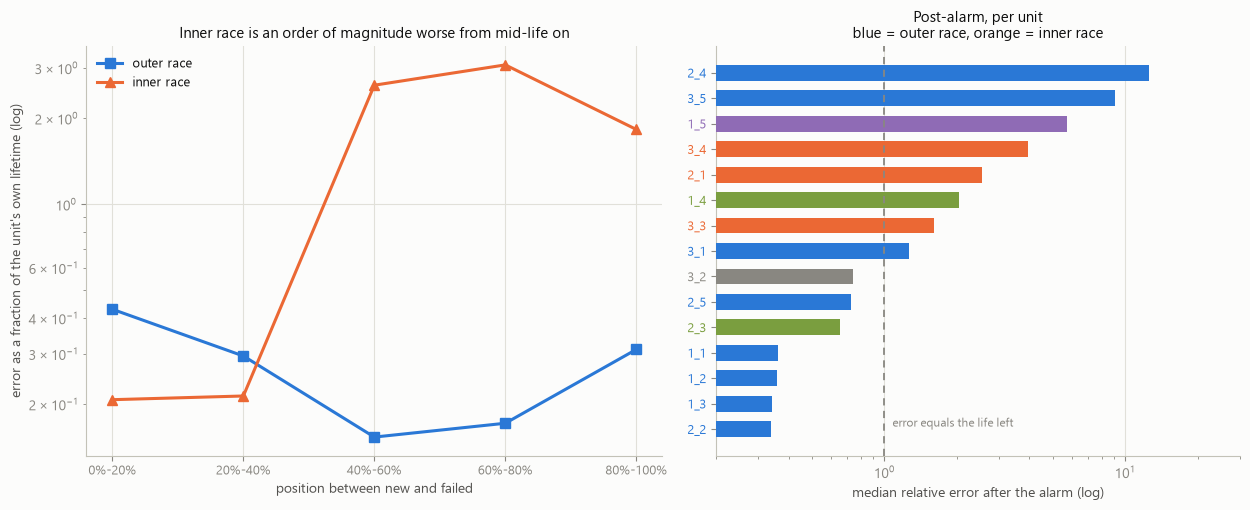

             mae   rel  late
fault                       
IR         45.70  2.55  1.00
IR+OR      77.06  5.73  1.00
OR         54.75  0.54  0.76
cage      122.35  1.35  0.67
compound  308.73  0.74  0.10


,fault,mae,rel,late
Bearing,,,,
Bearing1_1,OR,25,0.36,71%
Bearing1_2,OR,24,0.36,28%
Bearing1_3,OR,29,0.34,81%
Bearing1_4,cage,111,2.05,93%
Bearing1_5,IR+OR,77,5.73,100%
Bearing2_1,IR,46,2.55,100%
Bearing2_2,OR,31,0.34,40%
Bearing2_3,cage,133,0.66,41%
Bearing2_4,OR,116,12.51,100%


In [5]:
# Notebook 14 finding 4 required RUL to be reported per fault element. Here is why.
fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.6, 5.2),
                               gridspec_kw=dict(width_ratios=[1.1, 1]))
x = np.arange(len(LAB))
for race, mk in (("OR", "s"), ("IR", "^")):
    v = [cv[(cv["bin"] == k) & (cv["fault"] == race)]["err"].median() for k in LAB]
    axa.plot(x, v, color=FCOLOR[race], lw=2.2, marker=mk, ms=7, zorder=3,
             label=f"{'outer' if race == 'OR' else 'inner'} race")
axa.set_xticks(x, LAB, fontsize=9)
axa.set_yscale("log")
axa.set_xlabel("position between new and failed")
axa.set_ylabel("error as a fraction of the unit's own lifetime (log)")
axa.legend(fontsize=9, loc="upper left")
axa.set_title("Inner race is an order of magnitude worse from mid-life on", fontsize=10.5)

rows = []
for b in BEAR:
    d = P[b]
    s = d["post"]
    rows.append(dict(Bearing=b, fault=FAULT[b],
                     mae=np.abs(d["state"][s] - d["y"][s]).mean(),
                     rel=np.median(np.abs(d["state"][s] - d["y"][s]) / np.maximum(d["y"][s], 1)),
                     late=(d["state"][s] > d["y"][s]).mean()))
pe = pd.DataFrame(rows).set_index("Bearing")
order = sorted(BEAR, key=lambda b: pe.loc[b, "rel"])
y = np.arange(len(order))
axb.barh(y, [pe.loc[b, "rel"] for b in order], height=0.62, zorder=3,
         color=[FCOLOR[FAULT[b]] for b in order])
axb.axvline(1.0, color=MUTED, lw=1.3, ls=(0, (4, 3)), zorder=4)
axb.text(1.08, 0.1, "error equals the life left", fontsize=8.5, color=MUTED)
axb.set_yticks(y, [b.replace("Bearing", "") for b in order], fontsize=9.5)
for i, b in enumerate(order):
    axb.get_yticklabels()[i].set_color(FCOLOR[FAULT[b]])
axb.set_xscale("log")
axb.set_xlim(0.2, 30)
axb.grid(axis="y", visible=False)
axb.set_xlabel("median relative error after the alarm (log)")
axb.set_title("Post-alarm, per unit\nblue = outer race, orange = inner race", fontsize=10.5)
plt.tight_layout()
plt.show()

print(pe.groupby("fault")[["mae", "rel", "late"]].median().round(2).to_string())
pe.style.format({"mae": "{:.0f}", "rel": "{:.2f}", "late": "{:.0%}"})

Notebook 14's finding 4 required RUL to be conditioned on the fault element. This is the size of the effect. From mid-life onward inner race is an order of magnitude worse: scale-free error runs 0.21, 0.21, 2.61, 3.08, 1.83 across the five fifths, against outer race's 0.43, 0.30, 0.15, 0.17, 0.31. Outer race improves through mid-life as a prognostic should. Inner race diverges.

Post-alarm the same split holds. Median relative error is 0.54 for outer race against 2.55 for inner race, and outer race overstates remaining life on 76 % of snapshots while inner race does so on 100 %.

This is the third notebook in a row to find the same asymmetry. Inner-race faults are detected latest (9.2 % of life remaining, notebook 13), attributed wrongly first (38.4 % correct in the first fifth after the alarm, notebook 14), and now have their remaining life overestimated every time. The same units fail all three ways, and a system reporting one aggregate number for each stage would show none of it.

A single RUL figure should therefore not be issued for a bearing whose element is inner race or unknown. Notebook 15 established that "unknown" is not currently detectable, so the caveat has to attach to every inner-race call the system makes.

## A lower bound instead of a point estimate

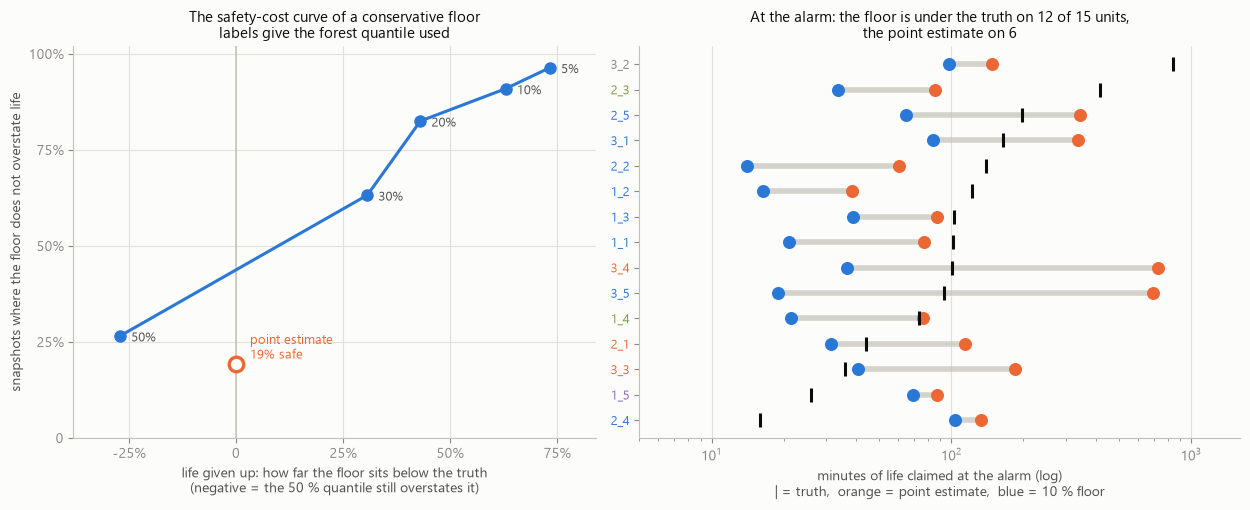

post-alarm, median unit: 10 % floor does not overstate life on 91% of snapshots against 19% for the point estimate, at the cost of understating it by 63%
at the alarm: point estimate optimistic on 9/15 units, 10 % floor on 3/15


,safe,give_up
q,,
0.050000,0.965,0.733
0.100000,0.910,0.630
0.200000,0.825,0.430
0.300000,0.633,0.307
0.500000,0.266,-0.271


In [6]:
# The forest already carries its own uncertainty: 300 trees, 300 votes on remaining life.
# Taking a low quantile of them needs no extra computation and turns a point estimate into a floor.
rows = []
for q in QS:
    safe, cost = [], []
    for b in BEAR:
        d = P[b]
        s = d["post"]
        p, y = d["q"][q][s], d["y"][s]
        safe.append((p <= y).mean())
        keep = y > 0
        cost.append(np.median((y[keep] - p[keep]) / y[keep]))
    rows.append(dict(q=q, safe=np.median(safe), give_up=np.median(cost)))
pt = [np.median([(P[b]["state"][P[b]["post"]] <= P[b]["y"][P[b]["post"]]).mean() for b in BEAR])]
band = pd.DataFrame(rows)

fig, (axa, axb) = plt.subplots(1, 2, figsize=(12.6, 5.2),
                               gridspec_kw=dict(width_ratios=[1, 1.15]))
axa.plot(band["give_up"], band["safe"], color=C_BLUE, lw=2.2, marker="o", ms=8, zorder=4)
for _, r in band.iterrows():
    axa.annotate(f"{r['q']:.0%}", (r["give_up"], r["safe"]), xytext=(8, -4),
                 textcoords="offset points", fontsize=9, color=INK2)
axa.scatter([0], pt, s=110, facecolors=SURFACE, edgecolors=C_ORANGE, linewidths=2.4, zorder=5)
axa.annotate(f"point estimate\n{pt[0]:.0%} safe", (0, pt[0]), xytext=(10, 4),
             textcoords="offset points", fontsize=9, color=C_ORANGE)
axa.set_xlabel("life given up: how far the floor sits below the truth\n"
               "(negative = the 50 % quantile still overstates it)")
axa.set_ylabel("snapshots where the floor does not overstate life")
axa.axvline(0, color=BASE, lw=1.1, zorder=2)
axa.set_xlim(-0.38, 0.84)
axa.set_ylim(0, 1.02)
axa.set_xticks([-0.25, 0, .25, .5, .75], ["-25%", "0", "25%", "50%", "75%"])
axa.set_yticks([0, .25, .5, .75, 1], ["0", "25%", "50%", "75%", "100%"])
axa.set_title("The safety-cost curve of a conservative floor\n"
              "labels give the forest quantile used", fontsize=10.5)

rows = []
for b in BEAR:
    d = P[b]
    i = np.flatnonzero(d["t"] == ALARM[b])[0]
    rows.append(dict(Bearing=b, fault=FAULT[b], truth=d["y"][i],
                     point=d["state"][i], floor=d["q"][0.10][i]))
al = pd.DataFrame(rows).set_index("Bearing")
order = sorted(BEAR, key=lambda b: -al.loc[b, "truth"])
y = np.arange(len(order))
for i, b in enumerate(order):
    r = al.loc[b]
    axb.plot([r["floor"], r["point"]], [i, i], color=BASE, lw=4, alpha=0.7,
             solid_capstyle="round", zorder=2)
    axb.scatter([r["point"]], [i], s=70, color=C_ORANGE, zorder=4)
    axb.scatter([r["floor"]], [i], s=70, color=C_BLUE, zorder=4)
    axb.scatter([r["truth"]], [i], s=95, marker="|", color=INK, linewidths=2.2, zorder=5)
axb.set_yticks(y, [b.replace("Bearing", "") for b in order], fontsize=9.5)
for i, b in enumerate(order):
    axb.get_yticklabels()[i].set_color(FCOLOR[FAULT[b]])
axb.invert_yaxis()
axb.set_xscale("log")
axb.set_xlim(5, 1600)
axb.grid(axis="y", visible=False)
axb.set_xlabel("minutes of life claimed at the alarm (log)\n"
               "| = truth,  orange = point estimate,  blue = 10 % floor")
axb.set_title("At the alarm: the floor is under the truth on 12 of 15 units,\n"
              "the point estimate on 6", fontsize=10.5)
plt.tight_layout()
plt.show()

print(f"post-alarm, median unit: 10 % floor does not overstate life on "
      f"{band.loc[band['q'] == 0.10, 'safe'].iloc[0]:.0%} of snapshots against {pt[0]:.0%} for the "
      f"point estimate, at the cost of understating it by "
      f"{band.loc[band['q'] == 0.10, 'give_up'].iloc[0]:.0%}")
print(f"at the alarm: point estimate optimistic on {(al['point'] > al['truth']).sum()}/15 units, "
      f"10 % floor on {(al['floor'] > al['truth']).sum()}/15")
band.set_index("q").style.format("{:.3f}")

A floor can be delivered where a point estimate cannot. The forest is an ensemble of 300 trees, each casting its own vote on remaining life. The spread across them is the model's own uncertainty, and a low quantile of it is a conservative bound that needs no extra computation.

Post-alarm, the 10 % quantile does not overstate remaining life on 91 % of snapshots for the median unit, against 19 % for the point estimate. The optimism that was systematic in the previous two figures is largely removed. The loss is stated on the same axes: the floor sits a median 63 % below the true remaining life, so it gives up a great deal of usable warning to be safe. The 20 % and 30 % quantiles are the intermediate settings. A deployment would pick a point on that curve, and this notebook does not pick one.

At the alarm the same reversal shows per unit: the point estimate is optimistic on 9 of 15 bearings, the floor on 3. Bearing3_5 is the clearest case: the point estimate promises 696 minutes when 93 remain, and the floor says 19.

The remaining-life question therefore has a usable half. The system cannot say how long a bearing will last, but it can say how long it will at least last, with a stated and tunable confidence. For a maintenance recommendation, a defensible lower bound is a better input than a point estimate that is optimistic every time it matters. It can also be phrased as "not before", which is what a scheduling decision needs.

## What this changes

1. RUL prediction on run-to-failure data is lifetime prediction. Elapsed time is known exactly, so `RUL_hat(t) = L_hat(t) − t` and the two errors are identical to the last decimal (verified at 0.000000 minutes across all 15 units). Any RUL result on this kind of data should be read as a claim about total life and compared with a clock.
2. Vibration adds nothing before the alarm and helps after it. Over a whole trajectory the two-channel state is worse than the learned clock it contains, 132 against 120 minutes. Post-alarm it wins, 78 against 89, and 57 against 80 when trained on post-alarm rows only. RUL belongs inside notebook 14's stage 2, not alongside stage 1.
3. The lifetime claim beats an operating-point prior on the outliers and loses on the ordinary units: mean error 211 minutes against 385, r² +0.86 against +0.29, but median error 117 against 88. Both estimators are floored at the minutes already survived, which is a lower bound that needs no model.
4. The estimate does not improve as failure approaches. Scale-free error is flat at 0.24–0.38 of a lifetime across every fifth of life while the life remaining falls from 90 % to 10 %, so error as a multiple of the remaining life grows from 0.36× to 3.75×. It is least useful when it is most needed.
5. The bias is one-directional and complete near the end. Predictions that overstate remaining life run 52 %, 63 %, 66 %, 100 %, 100 % across the five fifths. At the alarm the point estimate claims a median 1.73× the life that remained.
6. Inner race is an order of magnitude worse, which completes a pattern across three notebooks. Scale-free error from mid-life is 2.61/3.08/1.83 against outer race's 0.15/0.17/0.31. Post-alarm relative error is 2.55 against 0.54, and 100 % of inner-race predictions are optimistic against 76 %. Inner-race faults are detected latest (nb13), attributed wrongly first (nb14), and have their life overestimated every time (here).
7. A conservative floor is deliverable and a point estimate is not. The 10 % forest quantile is safe on 91 % of post-alarm snapshots against 19 % for the point estimate, at a median 63 % understatement, with a tunable curve behind it. At the alarm it is optimistic on 3 of 15 units rather than 9.